In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import genpareto
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

DATA = Path("..") / "data" / "procesados"
FIGURAS = Path("..") / "resultados" / "figuras" / "analisis_parametros"
FIGURAS.mkdir(exist_ok=True)

# Umbrales del modelo (src/train.py) y periodo de entrenamiento de la red
U = {"O3": 63.0, "SO2": 20.2, "PM2.5": 38.0}
INICIO, FIN = "2023-01-01", "2025-01-01"



Se unen las columnas con unidades (el problema de 2024) y se aplica la limpieza básica de la Etapa 2.
Se usa el mismo periodo con el que se entrenó la red (2023–2024).

In [2]:
ni = pd.read_csv(DATA / "datos_no_imputados.csv", low_memory=False)
for c in [c for c in ni.columns if " (" in c]:
    ni[c.split(" (")[0]] = ni[c.split(" (")[0]].fillna(ni[c])
ni["Fecha y hora"] = pd.to_datetime(ni["Fecha y hora"])

# Limpieza básica (Etapa 2)
for v in ["O3", "SO2", "PM2.5", "PM10"]:
    ni.loc[ni[v] < 0, v] = np.nan
ni.loc[ni["PM10"] >= 999, "PM10"] = np.nan
mal = ni["PM2.5"] > ni["PM10"]
ni.loc[mal, ["PM2.5", "PM10"]] = np.nan

obs = ni[(ni["Fecha y hora"] >= INICIO) & (ni["Fecha y hora"] < FIN)]
print(obs.shape)

(263111, 33)


 Validación del umbral

 Para cada umbral candidato $u$ se calcula el exceso medio $E(Y-u \mid Y>u)$.
Si la GPD es válida a partir de $u_0$, para $u>u_0$ la gráfica es una recta:
$E(Y-u\mid Y>u) = (\sigma_0+\xi u)/(1-\xi)$.

Se ajusta la GPD con cada umbral. Si el umbral es válido, $\xi$ y la escala modificada
$\sigma^* = \sigma_u - \xi u$ se mantienen aproximadamente constantes.

La línea punteada marca el umbral que usa el modelo.

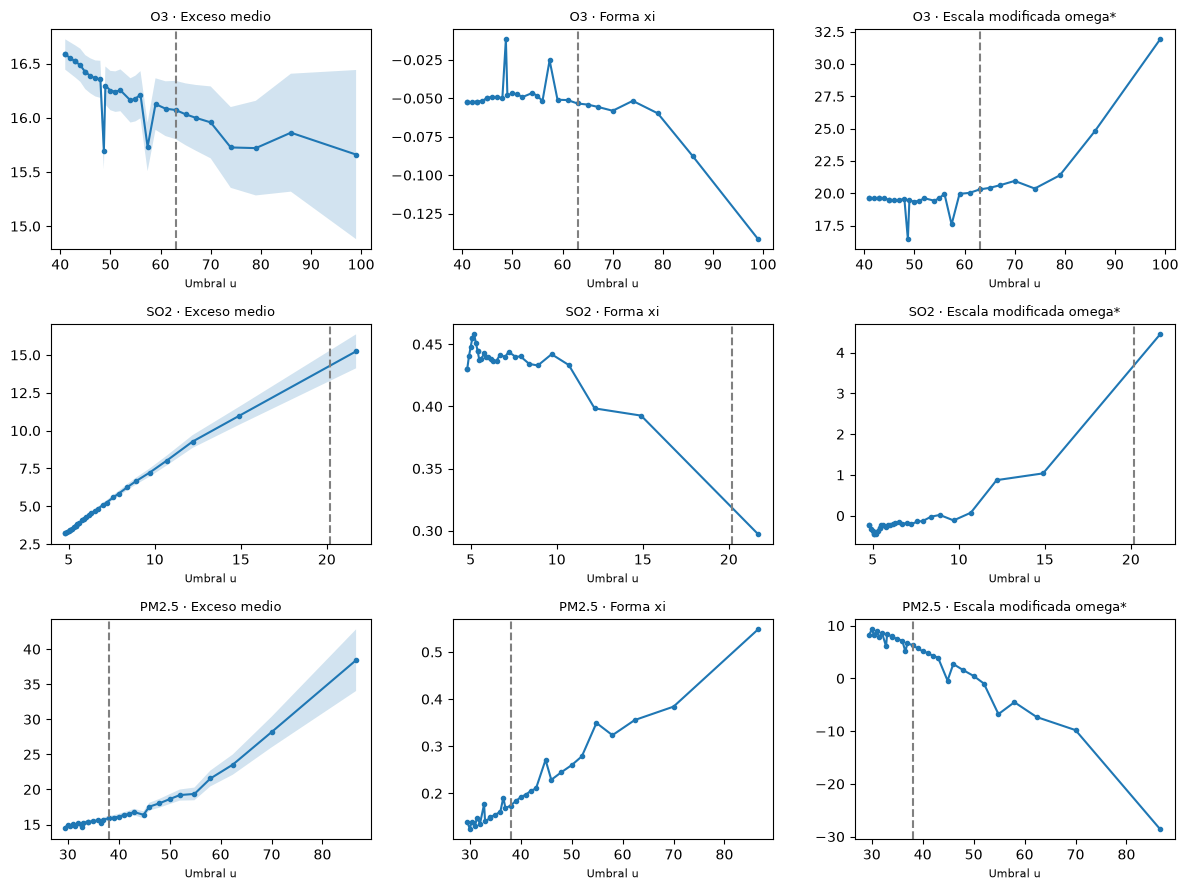

In [3]:
def vida_residual(x, umbrales):
    filas = []
    for u in umbrales:
        e = x[x > u] - u
        if len(e) < 30:
            continue
        xi, _, sigma = genpareto.fit(e, floc=0)
        filas.append({"u": u, "n": len(e), "media": e.mean(),
                      "ic": 1.96 * e.std() / np.sqrt(len(e)),
                      "xi": xi, "sigma_mod": sigma - xi * u})
    return pd.DataFrame(filas)

resultados = {}
fig, ejes = plt.subplots(3, 3, figsize=(12, 9))
for fila, var in enumerate(["O3", "SO2", "PM2.5"]):
    x = obs[var].dropna()
    umbrales = np.quantile(x, np.linspace(0.80, 0.995, 30))
    r = vida_residual(x, umbrales)
    resultados[var] = r
    titulos = ["Exceso medio", "Forma xi", "Escala modificada omega*"]
    for j, (col, tit) in enumerate(zip(["media", "xi", "sigma_mod"], titulos)):
        eje = ejes[fila, j]
        eje.plot(r["u"], r[col], "o-", ms=3)
        if col == "media":
            eje.fill_between(r["u"], r["media"] - r["ic"], r["media"] + r["ic"], alpha=0.2)
        eje.axvline(U[var], ls="--", color="gray")
        eje.set_title(f"{var} · {tit}", fontsize=9)
        eje.set_xlabel("Umbral u", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_umbral.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# Percentil que representa cada umbral y número de excesos
pd.DataFrame({var: {"u": U[var], "percentil": 100 * (obs[var].dropna() <= U[var]).mean(),
                    "excesos": int((obs[var] > U[var]).sum())} for var in U}).T.round(1)

,u,percentil,excesos
O3,63.0,95.1,12372.0
SO2,20.2,99.4,1434.0
PM2.5,38.0,89.6,19524.0


In [5]:
# Valores alrededor del umbral del modelo (para leer la estabilidad con números)
for var in U:
    r = resultados[var]
    print(var); print(r.iloc[(r["u"] - U[var]).abs().argsort()[:5]].sort_values("u").round(3).to_string(index=False)); print()

O3
   u     n  media    ic     xi  sigma_mod
59.0 15933 16.126 0.238 -0.051     19.953
61.0 14054 16.084 0.253 -0.051     20.027
63.0 12372 16.072 0.269 -0.053     20.293
65.0 10907 16.032 0.285 -0.054     20.415
67.0  9610 16.000 0.303 -0.056     20.612

SO2
   u    n  media    ic    xi  sigma_mod
 9.7 7814  7.224 0.269 0.442     -0.115
10.7 6164  8.021 0.326 0.433      0.073
12.2 4470  9.278 0.422 0.398      0.872
14.9 2891 10.976 0.595 0.393      1.038
21.7 1234 15.243 1.122 0.297      4.448

PM2.5
    u     n  media    ic    xi  sigma_mod
36.58 22421 15.176 0.305 0.191      5.116
37.00 21058 15.712 0.321 0.168      6.653
38.00 19524 15.878 0.341 0.174      6.303
39.00 18176 15.990 0.361 0.183      5.707
40.00 16902 16.128 0.382 0.192      5.137




Se ajusta una GPD constante a los excesos observados de cada estación y se compara con el promedio de lo que predice la red.
Si la red aprendió bien la cola de cada estación, ambos deberían parecerse.

In [8]:
comparacion = {}
for var in ["O3", "SO2"]:
    filas = {}
    for est, g in obs.groupby("Estacion"):
        e = g[var][g[var] > U[var]] - U[var]
        fila = {"excesos": len(e)}
        if len(e) >= 30:                       # con menos de 30 excesos el ajuste no es confiable
            xi, _, sigma = genpareto.fit(e, floc=0)
            fila.update(xi_obs=xi, sigma_obs=sigma)
        filas[est] = fila
    t = pd.DataFrame(filas).T
    comparacion[var] = t
    k = t.dropna()
comparacion["O3"].round(3)

,excesos,xi_obs,sigma_obs
CE,1178.0,-0.110,18.506
NE,585.0,0.039,12.849
NE2,286.0,0.057,12.989
NE3,212.0,0.091,7.413
NO,1051.0,-0.146,18.015
NO2,1437.0,-0.083,18.865
NO3,997.0,-0.113,17.980
NTE,818.0,0.002,13.965
NTE2,636.0,0.014,15.084
SE,773.0,-0.101,16.490


In [9]:
comparacion["SO2"].round(3)

,excesos,xi_obs,sigma_obs
CE,13.0,NaN,NaN
NE,36.0,0.409,8.459
NE2,124.0,0.194,7.169
NE3,31.0,0.133,9.618
NO,45.0,0.263,4.453
NO2,3.0,NaN,NaN
NO3,80.0,-0.096,12.307
NTE,19.0,NaN,NaN
NTE2,28.0,NaN,NaN
SE,15.0,NaN,NaN


Análisis de conglomerados de las estaciones

O3 · observado siluetas: {2: 0.69, 3: 0.68, 4: 0.51, 5: 0.4, 6: 0.34} → k = 2


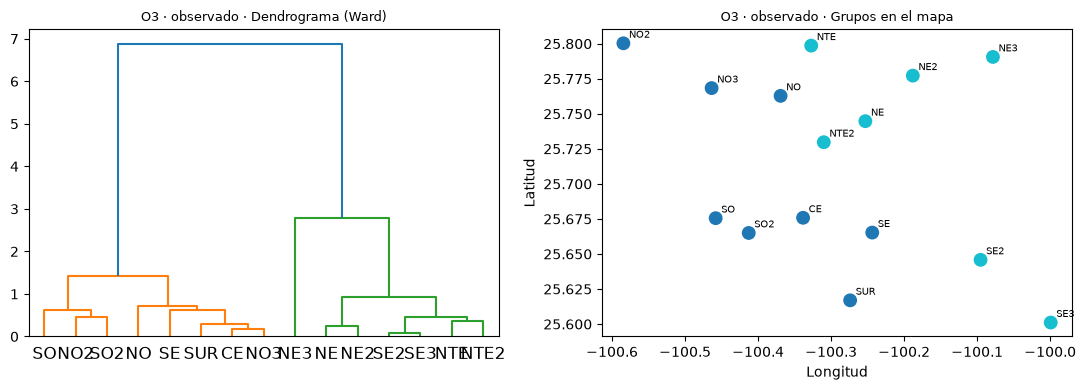

In [14]:
COORDS = pd.DataFrame(
    [[25.675833, -100.338333], [25.744722, -100.253056], [25.777222, -100.188056],
     [25.790556, -100.078333], [25.762778, -100.369167], [25.800278, -100.584444],
     [25.768333, -100.463611], [25.798611, -100.327222], [25.729722, -100.310000],
     [25.665278, -100.243611], [25.645833, -100.095278], [25.601111, -99.999167],
     [25.675556, -100.458056], [25.665000, -100.412778], [25.616944, -100.273889]],
    index=["CE", "NE", "NE2", "NE3", "NO", "NO2", "NO3", "NTE", "NTE2",
           "SE", "SE2", "SE3", "SO", "SO2", "SUR"], columns=["lat", "lon"])

# Tres conjuntos: parámetros de la red (O3 y SO2) y parámetros observados de O3
# (en SO2 hay estaciones con menos de 30 excesos, así que no se puede ajustar en todas)
CONJUNTOS = {
    "O3 · observado": ("O3",  ["xi_obs", "sigma_obs"]),
}
grupos, matrices = {}, {}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for fila, (nombre, (var, cols)) in enumerate(CONJUNTOS.items()):
    t = comparacion[var].loc[COORDS.index, cols].astype(float)
    X = StandardScaler().fit_transform(t)
    matrices[nombre] = X
    Z = linkage(X, method="ward")
    sil = {k: silhouette_score(X, fcluster(Z, k, "maxclust")) for k in range(2, 7)}
    k = max(sil, key=sil.get)
    grupos[nombre] = pd.Series(fcluster(Z, k, "maxclust"), index=COORDS.index)
    print(nombre, "siluetas:", {kk: round(v, 2) for kk, v in sil.items()}, "→ k =", k)

    dendrogram(Z, labels=list(COORDS.index), ax=ejes[0], color_threshold=Z[-k + 1, 2])
    ejes[0].set_title(f"{nombre} · Dendrograma (Ward)", fontsize=9)
    eje = ejes[1]
    eje.scatter(COORDS.lon, COORDS.lat, c=grupos[nombre], cmap="tab10", s=80)
    for est, (la, lo) in COORDS.iterrows():
        eje.annotate(est, (lo, la), xytext=(4, 4), textcoords="offset points", fontsize=7)
    eje.set_title(f"{nombre} · Grupos en el mapa", fontsize=9)
    eje.set_xlabel("Longitud"); eje.set_ylabel("Latitud")
fig.tight_layout()
fig.savefig(FIGURAS / "fig_conglomerados.png", dpi=300, bbox_inches="tight")
plt.show()



Si las estaciones cercanas tienen parámetros parecidos, ambas distancias están correlacionadas.
El valor p se obtiene permutando las estaciones 9,999 veces: no supone normalidad, lo que importa con solo 15 estaciones.



In [15]:
def haversine(c):
    la, lo = np.radians(c.lat.values), np.radians(c.lon.values)
    a = (np.sin((la[:, None] - la[None]) / 2) ** 2
         + np.cos(la[:, None]) * np.cos(la[None]) * np.sin((lo[:, None] - lo[None]) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))

def mantel(A, B, n=9999, seed=0):
    iu = np.triu_indices_from(A, 1)
    r0 = np.corrcoef(A[iu], B[iu])[0, 1]
    rng = np.random.default_rng(seed)
    mayores = sum(np.corrcoef(A[p][:, p][iu], B[iu])[0, 1] >= r0
                  for p in (rng.permutation(len(A)) for _ in range(n)))
    return r0, (mayores + 1) / (n + 1)

D_geo = haversine(COORDS)
for nombre, X in matrices.items():
    r, p = mantel(squareform(pdist(X)), D_geo)
    print(f"{nombre}: r de Mantel = {r:.3f}, valor p = {p:.4f}")

O3 · observado: r de Mantel = 0.377, valor p = 0.0060
